# CS 430 — Assignment 3: SLCM Classification Analysis

**Prediction question:** Can household and housing information identify households with $3,000 or more in past-due rent?

This notebook follows the nine numbered questions in the assignment. All models use one split and the same preprocessing specification. AI-assisted code and draft explanations were used; the student should verify, understand, and disclose that assistance before submitting.

## 1. Explore the dataset (7 points)
Load the CSV. Display five rows, data shape, column names, and missing-value counts. Identify one numerical and one categorical feature. Why must `past_due_rent` be excluded from the inputs?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, f1_score, ConfusionMatrixDisplay

df = pd.read_csv("SLCM_rent_arrears_student_clean.csv")
display(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Missing values by column:\n", df.isna().sum())

,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


Shape: (1754, 14)
Columns: ['record_id', 'adults_in_household', 'children_in_household', 'household_has_65plus', 'monthly_household_income', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter', 'monthly_rent', 'past_due_rent']
Missing values by column:
 record_id                       0
adults_in_household             0
children_in_household           0
household_has_65plus            0
monthly_household_income      108
income_sources                  0
employment_status               0
has_housing_voucher             0
eviction_in_progress            1
behind_on_utilities             7
main_reason_behind_on_rent     16
intake_quarter                  0
monthly_rent                    8
past_due_rent                   0
dtype: int64


**Answer:** `monthly_rent` is numerical, and `employment_status` is categorical. `past_due_rent` must be excluded because the target is calculated directly from it; including it would leak the answer into the model and make evaluation misleading.

## 2. Create the target (8 points)
Create `high_arrears` as 1 when `past_due_rent >= 3000` and 0 otherwise. Show counts and a bar chart. Which class is larger? Why might accuracy alone be misleading?

Class counts:
 high_arrears
0    1210
1     544
Name: count, dtype: int64


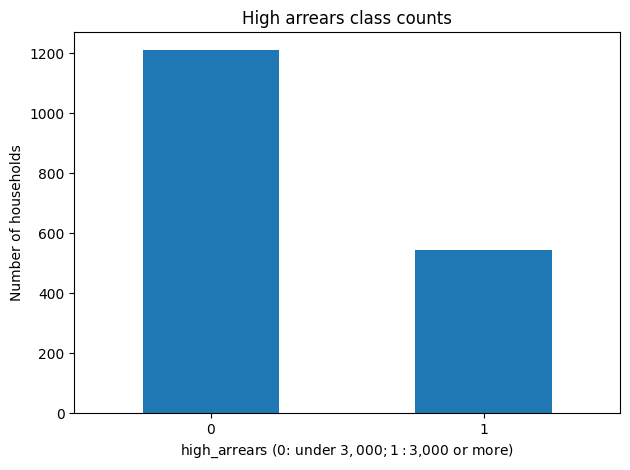

In [2]:
df["high_arrears"] = (df["past_due_rent"] >= 3000).astype(int)
counts = df["high_arrears"].value_counts().sort_index()
print("Class counts:\n", counts)
ax = counts.plot(kind="bar", rot=0, title="High arrears class counts")
ax.set_xlabel("high_arrears (0: under $3,000; 1: $3,000 or more)")
ax.set_ylabel("Number of households")
plt.tight_layout()
plt.show()

**Interpretation:** Class 0 is larger (1,210 households versus 544 in class 1). A model could achieve about 69% accuracy by always predicting class 0, yet fail to identify a single high-arrears household. This is why recall and F1 matter.

## 3. Select features and split (10 points)
Drop `record_id`, `past_due_rent`, and `high_arrears` from X. Split 80/20 with `random_state=42` and `stratify=y`. Why keep a separate test set?

In [3]:
X = df.drop(columns=["record_id", "past_due_rent", "high_arrears"])
y = df["high_arrears"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training:", X_train.shape, "Testing:", X_test.shape)
print("Train class proportions:\n", y_train.value_counts(normalize=True).sort_index())
print("Test class proportions:\n", y_test.value_counts(normalize=True).sort_index())

Training: (1403, 12) Testing: (351, 12)
Train class proportions:
 high_arrears
0    0.68995
1    0.31005
Name: proportion, dtype: float64
Test class proportions:
 high_arrears
0    0.689459
1    0.310541
Name: proportion, dtype: float64


**Answer:** The test set is held aside to measure how the trained models perform on data they have not seen. Keeping it separate from preprocessing fitting and model tuning helps avoid overly optimistic scores.

## 4. Build one reusable preprocessor (15 points)
Identify numerical and categorical columns. Median-impute and scale numeric columns; most-frequent-impute and one-hot encode categorical columns. Why is scaling helpful for KNN and SVC?

In [4]:
numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols),
])

Numerical columns: ['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']
Categorical columns: ['household_has_65plus', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter']


**Answer:** KNN uses distances between observations, and SVC is sensitive to feature scale. Standardizing numerical variables helps prevent features with large numerical ranges from dominating these calculations. The preprocessor is fitted inside each training pipeline, not on the full dataset.

## 5. Train the five classifiers (20 points)
Use the same preprocessor and split for Logistic Regression, KNN, Decision Tree, Random Forest, and SVC. Report test accuracy, recall, and F1 for class 1.

In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVC": SVC(),
}
results = []
fitted_models = {}
for name, classifier in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", classifier)])
    pipe.fit(X_train, y_train)
    predictions = pipe.predict(X_test)
    fitted_models[name] = pipe
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions, pos_label=1, zero_division=0),
        "F1": f1_score(y_test, predictions, pos_label=1, zero_division=0),
    })
    print(f"{name}: Accuracy={results[-1]['Accuracy']:.3f}, "
          f"Recall={results[-1]['Recall']:.3f}, F1={results[-1]['F1']:.3f}")

Logistic Regression: Accuracy=0.695, Recall=0.303, F1=0.382
KNN: Accuracy=0.681, Recall=0.376, F1=0.423
Decision Tree: Accuracy=0.695, Recall=0.330, F1=0.402


Random Forest: Accuracy=0.704, Recall=0.321, F1=0.402
SVC: Accuracy=0.707, Recall=0.229, F1=0.327


**Interpretation:** The five models have similar accuracy, but their recall and F1 differ. Accuracy should not be the sole selection criterion because the objective is to identify households with high arrears.

## 6. Compare the models (10 points)
Create one results table and a confusion matrix for the model with highest test F1. Which model catches the highest proportion of high-arrears households? What does a missed case mean for SLCM?

,Model,Accuracy,Recall,F1
0,Logistic Regression,0.695,0.303,0.382
1,KNN,0.681,0.376,0.423
2,Decision Tree,0.695,0.330,0.402
3,Random Forest,0.704,0.321,0.402
4,SVC,0.707,0.229,0.327


Highest test F1: KNN
Highest test recall: KNN


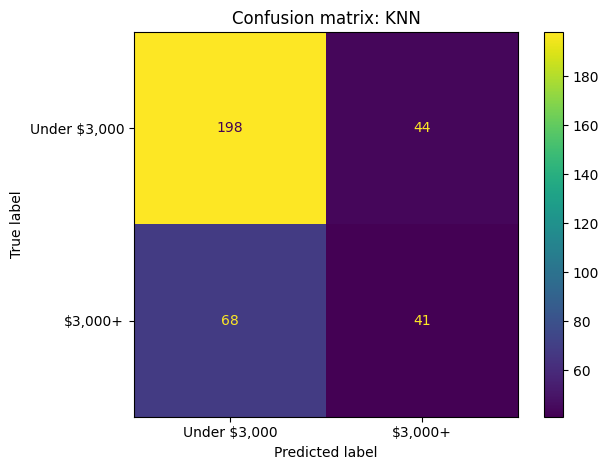

In [6]:
results_df = pd.DataFrame(results)
display(results_df.round(3))
best_f1_row = results_df.loc[results_df["F1"].idxmax()]
best_recall_row = results_df.loc[results_df["Recall"].idxmax()]
print("Highest test F1:", best_f1_row["Model"])
print("Highest test recall:", best_recall_row["Model"])
ConfusionMatrixDisplay.from_estimator(
    fitted_models[best_f1_row["Model"]], X_test, y_test,
    labels=[0, 1], display_labels=["Under $3,000", "$3,000+"]
)
plt.title(f"Confusion matrix: {best_f1_row['Model']}")
plt.tight_layout()
plt.show()

**Interpretation:** KNN has the highest test recall (about 0.376) and the highest test F1 (about 0.423) in this baseline comparison. A missed case (false negative) is a household with at least $3,000 past due that the model labels as below the threshold; SLCM could overlook that household for additional outreach.

## 7. Try a small GridSearchCV (15 points)
Tune KNN `n_neighbors=[3,5,7]` and Random Forest `max_depth=[3,5,None]`, with `cv=3`, `scoring="f1"`, and training data only. Which has higher best cross-validation F1? Why train-only?

In [7]:
knn_search = GridSearchCV(
    Pipeline([("preprocessor", preprocessor), ("model", KNeighborsClassifier())]),
    {"model__n_neighbors": [3, 5, 7]}, cv=3, scoring="f1"
)
knn_search.fit(X_train, y_train)
print("KNN best parameters:", knn_search.best_params_)
print("KNN best CV F1:", round(knn_search.best_score_, 3))

rf_search = GridSearchCV(
    Pipeline([("preprocessor", preprocessor),
              ("model", RandomForestClassifier(n_estimators=100, random_state=42))]),
    {"model__max_depth": [3, 5, None]}, cv=3, scoring="f1"
)
rf_search.fit(X_train, y_train)
print("Random Forest best parameters:", rf_search.best_params_)
print("Random Forest best CV F1:", round(rf_search.best_score_, 3))

KNN best parameters: {'model__n_neighbors': 7}
KNN best CV F1: 0.485


Random Forest best parameters: {'model__max_depth': None}
Random Forest best CV F1: 0.457


**Answer:** KNN has the higher best cross-validation F1 (about 0.485 versus 0.457 for Random Forest). GridSearchCV uses only training data so the test set stays untouched for an independent evaluation; choosing settings using test results would bias that evaluation. These CV scores are not directly interchangeable with the baseline test scores.

## 8. Interpret your comparison (8 points)
In 4–5 sentences, identify the most promising model using F1 and recall. Did a more complex model necessarily do better? What errors should SLCM watch?

**Draft interpretation (review in your own words):** KNN is the most promising of the five baseline models because it has the highest test F1 (0.423) and recall (0.376). Its accuracy is about 0.681, which is not the highest, but its stronger recall is useful when the goal is to find high-arrears households. A more complex model did not necessarily do better, since Random Forest and SVC had lower F1 scores than KNN. SLCM should pay special attention to false negatives, which could mean missing households that need outreach. False positives also matter because they may use limited staff time for follow-up.

## 9. Recommendation to SLCM (7 points)
Write 4–5 sentences for a non-technical audience: prediction goal, performance, practical insight, limitation, and responsible use.

I have tested whether household and housing information can help flag households with $3,000 or more in overdue rent. The KNN model performed best by F1 in our initial comparison, but it identified only about 38% of the households actually above the threshold in the test set. This suggests the model may help prioritize extra outreach, but it would miss many households if used by itself. The data and model may not represent every household or situation, and a prediction is not proof that any feature causes rent arrears. Predictions must not be used alone to decide eligibility for assistance.